# Flight endpoint statistics

Measure the final ADS-B point's distance and barometric-altitude difference from the inferred landing airport, and check whether the final message reports the aircraft on the ground.

In [ ]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from airports.airport_lookup import AirportLookup
from data_engineering.adsb.read_adsb import read_adsb
from flights_airport_nn.features.ground_truth_join_segmentation_algorithm import flights_features_df
from planequery_data.utils import haversine

target_date = date(2026, 3, 1)
df = flights_features_df(target_date)
df

Loading airports from /Volumes/T2-SSD/planequery/data/raw/ourairports/airports.csv
Stats for algorithm-no-airports:ground_truth: {'true_positive': 2311, 'false_positive': 1, 'false_negative': 2, 'precision': 0.9995674740484429, 'recall': 0.9991353220925205, 'f1': 0.9993513513513512, 'takeoff_airport_ident_total_count': 2311, 'takeoff_airport_ident_match_count': 2302, 'takeoff_airport_ident_incorrect_match_count': 9, 'takeoff_airport_ident_match_pct': 0.9961055819991346, 'landing_airport_ident_total_count': 2311, 'landing_airport_ident_match_count': 2285, 'landing_airport_ident_incorrect_match_count': 26, 'landing_airport_ident_match_pct': 0.988749459108611, 'airport_ident_total_count': 2311, 'airport_ident_match_count': 2276, 'airport_ident_incorrect_match_count': 35, 'airport_ident_match_pct': 0.9848550411077456}
Stats CSV saved to /Volumes/T2-SSD/planequery/data/experiments/comparison/2026-09-11_13-44_595bb37_flights_evaluation.csv


icao,callsign,registration,takeoff_time,takeoff_airport_ident,landing_time,landing_airport_ident,first_message_time,first_lat,first_lon,first_baro_altitude_ft,first_geom_altitude_ft,last_message_time,last_lat,last_lon,last_baro_altitude_ft,last_geom_altitude_ft,pia,ladd,military,interesting,aircraft_type,owner,aircraft_description,category
str,str,str,datetime[ms],str,datetime[ms],str,datetime[ms],f64,f64,i64,i64,datetime[ms],f64,f64,i64,i64,bool,bool,bool,bool,str,str,str,str
"""a008c9""","""DAL2519""","""N101DU""",2026-03-01 00:01:37.690,"""KRDU""",2026-03-01 02:32:58.440,"""KMSP""",2026-03-01 00:01:37.690,35.877437,-78.798387,725,null,2026-03-01 02:32:58.440,44.887482,-93.208335,null,null,false,false,false,false,"""BCS1""","""BANK OF UTAH TRUSTEE""","""AIRBUS A220-100""","""A3"""
"""a008c9""","""DAL2002""","""N101DU""",2026-03-01 16:44:30.240,"""KMSP""",2026-03-01 18:49:47.320,"""KCHS""",2026-03-01 16:44:30.240,44.881944,-93.240766,275,null,2026-03-01 18:49:47.320,32.922115,-80.055019,50,null,false,false,false,false,"""BCS1""","""BANK OF UTAH TRUSTEE""","""AIRBUS A220-100""","""A3"""
"""a008c9""","""DAL2002""","""N101DU""",2026-03-01 20:05:49.310,"""KCHS""",2026-03-01 22:56:09.940,"""KMSP""",2026-03-01 20:05:49.310,32.882126,-80.047046,550,null,2026-03-01 22:56:09.940,44.893387,-93.222002,450,null,false,false,false,false,"""BCS1""","""BANK OF UTAH TRUSTEE""","""AIRBUS A220-100""","""A3"""
"""a00c7a""","""DAL2607""","""N102DN""",2026-03-01 01:11:04.430,"""KMSP""",2026-03-01 03:45:58.360,"""KSLC""",2026-03-01 01:11:04.430,44.883682,-93.224683,550,null,2026-03-01 03:45:58.360,40.784626,-111.962097,null,null,false,false,false,false,"""A321""","""DELTA AIR LINES INC""","""AIRBUS A-321""","""A3"""
"""a00c7a""","""DAL2903""","""N102DN""",2026-03-01 17:10:01.980,"""KSLC""",2026-03-01 18:57:29.370,"""KMCI""",2026-03-01 17:10:01.980,40.801895,-111.976318,4100,null,2026-03-01 18:57:29.370,39.295349,-94.78009,1525,null,false,false,false,false,"""A321""","""DELTA AIR LINES INC""","""AIRBUS A-321""","""A3"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ade191""","""DAL2024""","""N994AT""",2026-03-01 13:30:19.660,"""KATL""",2026-03-01 14:57:43.080,"""KXNA""",2026-03-01 13:30:19.660,33.646774,-84.412723,750,null,2026-03-01 14:57:43.080,36.267312,-94.300212,1200,null,false,false,false,false,"""B712""","""DELTA AIR LINES INC""","""BOEING 717-200""","""A3"""
"""ade191""","""DAL2024""","""N994AT""",2026-03-01 16:08:36.360,"""KXNA""",2026-03-01 17:25:53.320,"""KATL""",2026-03-01 16:08:36.360,36.277451,-94.304867,1125,null,2026-03-01 17:25:53.320,33.631828,-84.430772,null,null,false,false,false,false,"""B712""","""DELTA AIR LINES INC""","""BOEING 717-200""","""A3"""
"""ade191""","""DAL1359""","""N994AT""",2026-03-01 18:34:05.680,"""KATL""",2026-03-01 19:17:04.590,"""KECP""",2026-03-01 18:34:05.680,33.634689,-84.416367,775,null,2026-03-01 19:17:04.590,30.344009,-85.789436,-50,null,false,false,false,false,"""B712""","""DELTA AIR LINES INC""","""BOEING 717-200""","""A3"""


## Build endpoint features

The segmentation algorithm's `last_message_time` is an exact ADS-B timestamp. Joining on `(icao, last_message_time)` therefore recovers `last_on_ground` without an approximate time match. Flights with missing airport metadata or barometric altitude remain in the result with null derived values.

In [2]:
airport_lookup = AirportLookup()
airport_metadata = pl.DataFrame(
    [
        {
            "landing_airport_ident": airport.ident,
            "landing_airport_lat": airport.lat,
            "landing_airport_lon": airport.lon,
            "landing_airport_elevation_ft": airport.elevation_ft,
        }
        for airport in airport_lookup.ident_index.values()
    ]
).with_columns(pl.col("landing_airport_elevation_ft").cast(pl.Int64))

In [3]:
last_message_rows = (
    read_adsb(
        target_date,
        columns=["icao", "time", "on_ground"],
        icaos=df.get_column("icao").drop_nulls().unique().to_list(),
        source="adsblol",
    )
    .select(
        "icao",
        pl.col("time").alias("last_message_time"),
        pl.col("on_ground").alias("last_on_ground"),
    )
    .unique(subset=["icao", "last_message_time"], keep="last")
)

In [4]:
distance_to_expr = pl.struct(
    "landing_airport_lat", "landing_airport_lon", "last_lat", "last_lon"
).map_elements(
    lambda row: haversine(
        row["landing_airport_lat"],
        row["landing_airport_lon"],
        row["last_lat"],
        row["last_lon"],
    )
    if all(value is not None for value in row.values())
    else None,
    return_dtype=pl.Float64,
).alias("distance_to_km")

endpoint_features = (
    df.join(airport_metadata, on="landing_airport_ident", how="left")
    .join(last_message_rows, on=["icao", "last_message_time"], how="left")
    .with_columns(
        distance_to_expr,
        (
            pl.col("last_baro_altitude_ft")
            - pl.col("landing_airport_elevation_ft")
        ).alias("altitude_difference_ft"),
    )
    .select(
        "icao",
        "landing_time",
        "landing_airport_ident",
        "last_message_time",
        "last_lat",
        "last_lon",
        "last_baro_altitude_ft",
        "landing_airport_elevation_ft",
        "distance_to_km",
        "altitude_difference_ft",
        "last_on_ground",
    )
)
endpoint_features

icao,landing_time,landing_airport_ident,last_message_time,last_lat,last_lon,last_baro_altitude_ft,landing_airport_elevation_ft,distance_to_km,altitude_difference_ft,last_on_ground
str,datetime[ms],str,datetime[ms],f64,f64,i64,i64,f64,i64,bool
"""a008c9""",2026-03-01 02:32:58.440,"""KMSP""",2026-03-01 02:32:58.440,44.887482,-93.208335,null,841,1.338963,null,true
"""a008c9""",2026-03-01 18:49:47.320,"""KCHS""",2026-03-01 18:49:47.320,32.922115,-80.055019,50,46,3.287789,4,false
"""a008c9""",2026-03-01 22:56:09.940,"""KMSP""",2026-03-01 22:56:09.940,44.893387,-93.222002,450,841,1.479703,-391,false
"""a00c7a""",2026-03-01 03:45:58.360,"""KSLC""",2026-03-01 03:45:58.360,40.784626,-111.962097,null,4227,1.56832,null,true
"""a00c7a""",2026-03-01 18:57:29.370,"""KMCI""",2026-03-01 18:57:29.370,39.295349,-94.78009,1525,1026,5.739776,499,false
…,…,…,…,…,…,…,…,…,…,…
"""ade191""",2026-03-01 14:57:43.080,"""KXNA""",2026-03-01 14:57:43.080,36.267312,-94.300212,1200,1287,1.726097,-87,false
"""ade191""",2026-03-01 17:25:53.320,"""KATL""",2026-03-01 17:25:53.320,33.631828,-84.430772,null,1026,0.59551,null,true
"""ade191""",2026-03-01 19:17:04.590,"""KECP""",2026-03-01 19:17:04.590,30.344009,-85.789436,-50,69,1.565219,-119,false


## Summary statistics

In [5]:
numeric_features = ["distance_to_km", "altitude_difference_ft"]
summary_stats = pl.DataFrame(
    [
        {
            "feature": feature,
            **endpoint_features.select(
                pl.len().alias("total_flights"),
                pl.col(feature).count().alias("non_null_count"),
                pl.col(feature).null_count().alias("null_count"),
                pl.col(feature).mean().alias("mean"),
                pl.col(feature).std().alias("std"),
                pl.col(feature).min().alias("min"),
                pl.col(feature).quantile(0.25).alias("p25"),
                pl.col(feature).median().alias("median"),
                pl.col(feature).quantile(0.75).alias("p75"),
                pl.col(feature).quantile(0.90).alias("p90"),
                pl.col(feature).quantile(0.95).alias("p95"),
                pl.col(feature).quantile(0.99).alias("p99"),
                pl.col(feature).max().alias("max"),
            ).row(0, named=True),
        }
        for feature in numeric_features
    ]
)
summary_stats

feature,total_flights,non_null_count,null_count,mean,std,min,p25,median,p75,p90,p95,p99,max
str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""distance_to_km""",2312,2311,1,2.104195,5.458772,0.007349,0.716964,1.383868,1.993985,3.262786,4.444263,14.818089,94.296341
"""altitude_difference_ft""",2312,584,1728,337.224315,1593.15546,-616.0,-201.0,-10.5,273.0,799.0,1795.0,9477.0,17142.0


In [6]:
on_ground_stats = endpoint_features.select(
    pl.len().alias("total_flights"),
    pl.col("last_on_ground").count().alias("non_null_count"),
    pl.col("last_on_ground").null_count().alias("null_count"),
    pl.col("last_on_ground").eq(True).sum().alias("true_count"),
    pl.col("last_on_ground").eq(False).sum().alias("false_count"),
    pl.col("last_on_ground").cast(pl.Float64).mean().alias("true_fraction"),
    (pl.col("last_on_ground").cast(pl.Float64).mean() * 100).alias("true_percent"),
)
on_ground_stats

total_flights,non_null_count,null_count,true_count,false_count,true_fraction,true_percent
u32,u32,u32,u32,u32,f64,f64
2312,2312,0,1728,584,0.747405,74.740484


## Distributions

The numeric plots are clipped to their 1st–99th percentile range so a few extreme endpoints do not hide the main distribution. The summary table above retains the full, unclipped data.

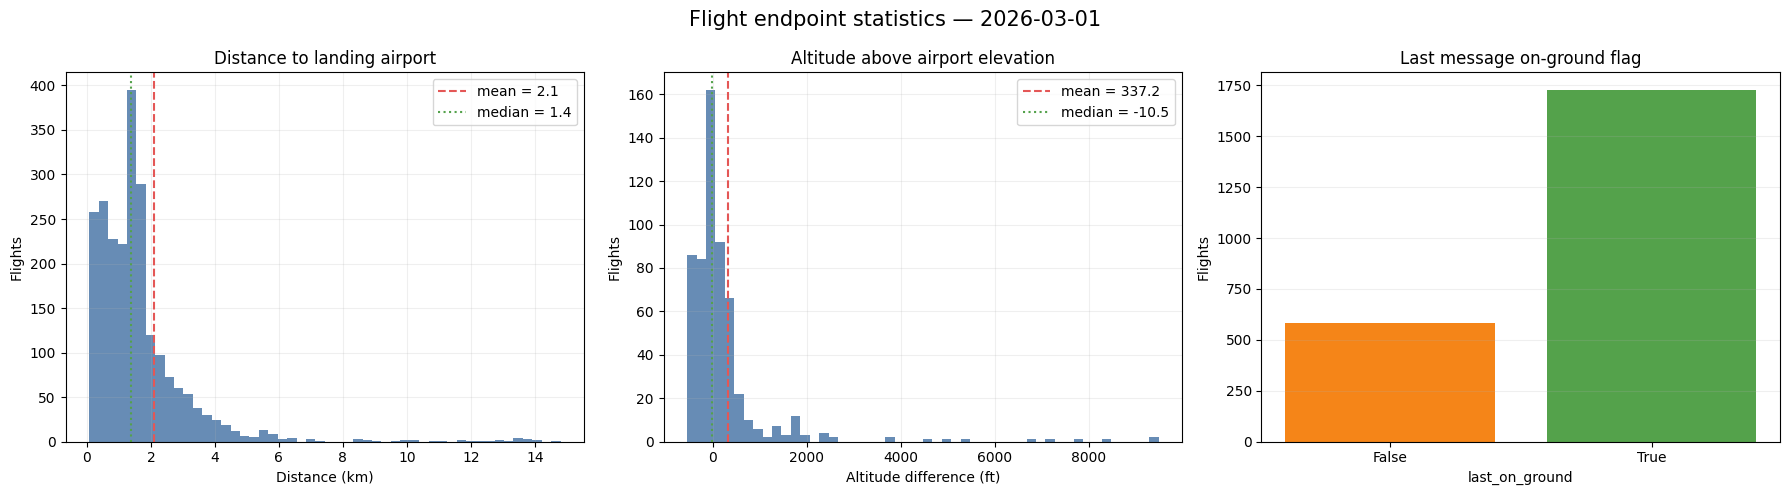

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_specs = [
    ("distance_to_km", "Distance to landing airport", "Distance (km)"),
    ("altitude_difference_ft", "Altitude above airport elevation", "Altitude difference (ft)"),
]

for ax, (feature, title, xlabel) in zip(axes[:2], plot_specs):
    values = endpoint_features.get_column(feature).drop_nulls().to_numpy()
    if values.size:
        lower, upper = np.quantile(values, [0.01, 0.99])
        plotted = values[(values >= lower) & (values <= upper)]
        ax.hist(plotted, bins=50, color="#4C78A8", alpha=0.85)
        ax.axvline(values.mean(), color="#E45756", linestyle="--", label=f"mean = {values.mean():,.1f}")
        ax.axvline(np.median(values), color="#54A24B", linestyle=":", label=f"median = {np.median(values):,.1f}")
        ax.legend()
    else:
        ax.text(0.5, 0.5, "No non-null values", ha="center", va="center", transform=ax.transAxes)
    ax.set(title=title, xlabel=xlabel, ylabel="Flights")
    ax.grid(alpha=0.2)

ground_values = endpoint_features.get_column("last_on_ground").drop_nulls()
true_count = int(ground_values.sum()) if len(ground_values) else 0
false_count = len(ground_values) - true_count
axes[2].bar(["False", "True"], [false_count, true_count], color=["#F58518", "#54A24B"])
axes[2].set(title="Last message on-ground flag", xlabel="last_on_ground", ylabel="Flights")
axes[2].grid(axis="y", alpha=0.2)

fig.suptitle(f"Flight endpoint statistics — {target_date.isoformat()}", fontsize=15)
fig.tight_layout()
plt.show()